# Hotel booking cancellation: model training, comparison & selection

**VoidMain Technologies AI internship · Task 3: Machine Learning Application & Model Evaluation**

This notebook walks through the whole modelling workflow, top to bottom. It calls the same
functions as `python main.py` (everything lives in `src/`). Cheap steps run live here. The
expensive ones (tuning, learning curves, temporal check) are loaded from the results that
`main.py` saved, so the notebook runs in about a minute and always shows the same numbers as
the README and the web app.

| Brief requirement | Section |
|---|---|
| Practical classification problem | 1 |
| Appropriate validation | 3 |
| Multiple algorithms + baseline | 4 |
| Relevant metrics | 4, 5 |
| Hyperparameter tuning | 6 |
| Over/underfitting | 7 |
| Justified model selection | 8 |
| Threshold, final test evaluation, explainability | 9, 10, 11 |

In [1]:
import json
import sys
from pathlib import Path

import joblib
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config
from src.evaluate import compute_metrics, report_dict
from src.models import build_model_zoo
from src.train import cross_validate_model, prepare_dataset

config.setup_logging()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 4)
FIG = config.FIGURES_DIR
summary = json.loads(config.APP_DASHBOARD_CACHE.read_text(encoding="utf-8"))
metric, label = config.PRIMARY_METRIC, config.METRIC_LABELS[config.PRIMARY_METRIC]

## 1. Problem

Predict `is_canceled` (1 = canceled) for a hotel booking at the time it is made. A hotel that
knows which bookings will cancel can overbook just enough to keep rooms full: missed
cancellations leave rooms empty, false alarms mean relocating overbooked guests.

Data: *Hotel booking demand* (Antonio, Almeida & Nunes, 2019), real bookings from a city
hotel and a resort hotel in Portugal, arrivals July 2015 to August 2017.

## 2. Data: reused from Task 2

Cleaning and feature engineering are **copied unchanged from Task 2**
([hotel-booking-preprocessing](https://github.com/Krishna141414/hotel-booking-preprocessing)):
drop exact duplicates, zero-guest rows, negative ADR and impossible counts, cap extreme ADR,
fill structural missing values, and add 10 row-wise features. This project only adds what
modelling needs: the leakage columns are dropped right away and the split is fixed.

In [2]:
dataset = prepare_dataset()
print(f"Raw: {dataset.raw_shape[0]:,} rows x {dataset.raw_shape[1]} columns")
print(f"Clean + engineered: {len(dataset.featured):,} rows")
print(f"Train / test: {len(dataset.train_rows):,} / {len(dataset.test_rows):,}")
print(f"Cancel rate train / test: {dataset.y_train.mean():.3%} / {dataset.y_test.mean():.3%}")
print(
    f"Model inputs: {len(dataset.groups.all)} "
    f"({len(dataset.groups.numeric)} numeric, {len(dataset.groups.binary)} binary, "
    f"{len(dataset.groups.categorical)} categorical)"
)

18:39:49 | INFO    | src.data       | Loaded 119,390 rows x 32 columns from hotel_bookings.csv


18:39:49 | INFO    | src.data       | -> Drop zero-guest bookings


18:39:49 | INFO    | src.data       | Zero-guest bookings dropped: 180


18:39:49 | INFO    | src.data       | -> Drop negative ADR


18:39:49 | INFO    | src.data       | Negative-ADR rows dropped: 1


...

18:39:50 | INFO    | src.data       | Cleaning done: 119,390 -> 87,208 rows (32,182 removed, 27.0%)


18:39:50 | INFO    | src.features   | Engineered 10 features: ['total_nights', 'total_guests', 'has_children', 'adr_per_person', 'stay_value', 'arrival_month_num', 'arrival_weekday', 'arrival_season', 'is_domestic', 'previous_cancel_ratio']


18:39:50 | INFO    | src.features   | Shape after feature engineering: 87,208 rows x 41 columns


18:39:50 | INFO    | src.train      | Split: 69,766 train / 17,442 test rows (stratified, cancel rate 27.5% / 27.5%); 33 inputs


Raw: 119,390 rows x 32 columns
Clean + engineered: 87,208 rows
Train / test: 69,766 / 17,442
Cancel rate train / test: 27.511% / 27.514%
Model inputs: 33 (18 numeric, 5 binary, 10 categorical)


### Leakage review

* `reservation_status` / `reservation_status_date` reveal the outcome, so they are dropped right after cleaning.
* `assigned_room_type` is set at check-in (canceled bookings never get there) and is **dropped**.
* `booking_changes` is counted up to the outcome date, so early cancellations have had less time to change. It's **dropped**, the safer option.
* `days_in_waiting_list` is known once the booking is confirmed and is **kept**.

The ablation below (from `main.py`) is the evidence: adding the two post-booking columns
lifts the CV score, which is the classic sign that they carry outcome information.

In [3]:
pd.DataFrame(summary["ablation"]).set_index("variant")

,inputs,pr_auc,pr_auc_std,roc_auc,delta
variant,,,,,
Selected features (final),33,0.7794,0.0051,0.9038,0.0000
+ booking_changes,34,0.7859,0.0046,0.9062,0.0065
+ assigned_room_type,34,0.7926,0.0048,0.9101,0.0132
+ both post-booking columns,35,0.7985,0.0047,0.9124,0.0191
- days_in_waiting_list,32,0.7791,0.0051,0.9037,-0.0003
- country & is_domestic,31,0.7146,0.0057,0.8515,-0.0648


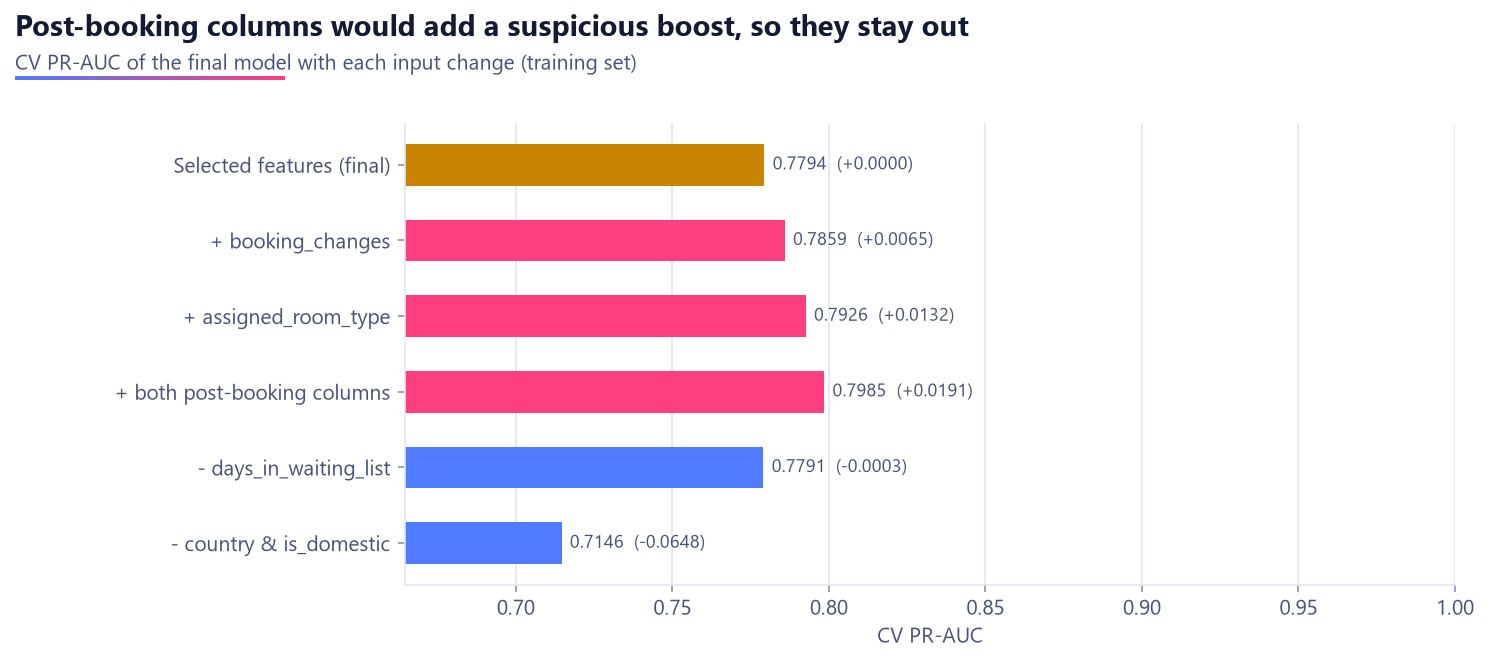

In [4]:
display(Image(FIG / "15_leakage_ablation.png", width=820))

## 3. Validation setup

* **Stratified 80/20 train/test split** (seed 42, same split as Task 2). The test set is used
  **once**, after the final model and threshold are frozen.
* **Stratified 5-fold cross-validation** on the training set for every comparison, tuning and
  selection decision. All models use the same folds.
* **Pipelines everywhere**: scaling, the log1p choice and one-hot categories are fitted inside
  each training fold, so validation folds never leak into preprocessing.
* **Imbalance (27.5% canceled)**: stratified splits, `class_weight="balanced"` where the
  algorithm supports it, and PR-AUC as the primary metric rather than accuracy.
* **Extra realism check**: a temporal split (train on earlier arrivals, test on the latest
  20%) in section 12.

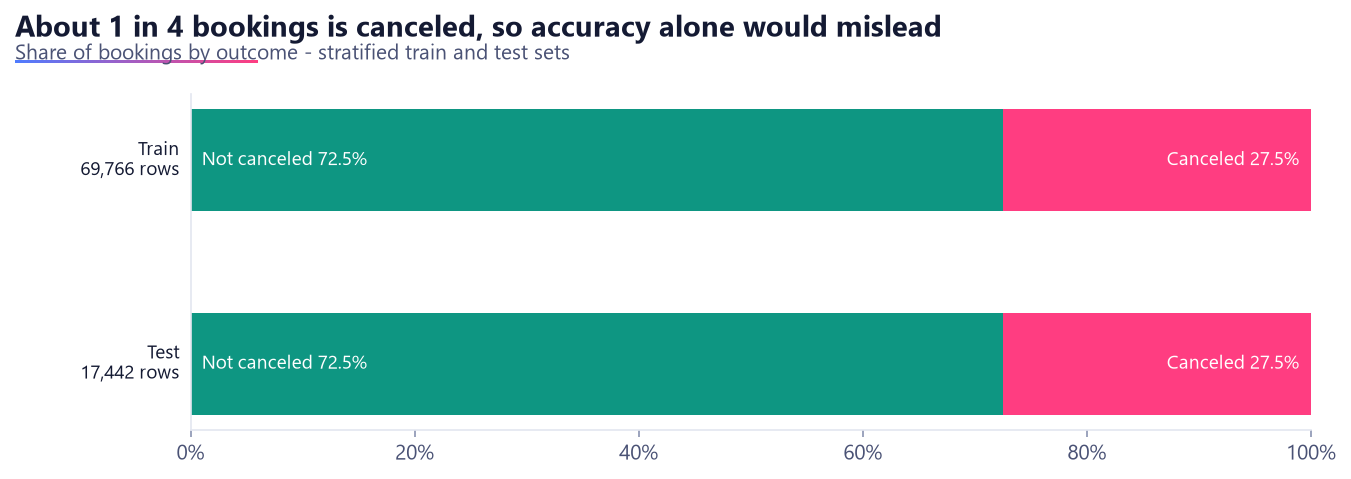

In [5]:
display(Image(FIG / "01_class_balance.png", width=760))

## 4. Baseline + five algorithms (5-fold CV)

As a live demonstration, the baseline and Logistic Regression are cross-validated here. The
numbers match the saved run because the folds are seeded.

In [6]:
zoo = build_model_zoo(dataset.groups)
live = {
    k: cross_validate_model(k, zoo[k], dataset.x_train, dataset.y_train)
    for k in ["dummy", "logreg"]
}
pd.DataFrame(
    {
        r.name: {m: f"{r.cv[m]['mean']:.4f} ± {r.cv[m]['std']:.4f}" for m in config.METRICS}
        for r in live.values()
    }
).rename(index=config.METRIC_LABELS)

18:39:50 | INFO    | src.models     | Model zoo: Dummy (most frequent), Logistic Regression, Decision Tree, Random Forest, HistGradientBoosting, K-Nearest Neighbors


18:39:53 | INFO    | src.train      |   Dummy (most frequent)          CV PR-AUC 0.2751 +/- 0.0000 | train 0.2751 | fold fit 0.4s


18:39:56 | INFO    | src.train      |   Logistic Regression            CV PR-AUC 0.6826 +/- 0.0140 | train 0.6828 | fold fit 1.4s


,Dummy (most frequent),Logistic Regression
Accuracy,0.7249 ± 0.0000,0.7659 ± 0.0072
Precision,0.0000 ± 0.0000,0.5512 ± 0.0094
Recall,0.0000 ± 0.0000,0.8028 ± 0.0103
F1,0.0000 ± 0.0000,0.6536 ± 0.0096
ROC-AUC,0.5000 ± 0.0000,0.8580 ± 0.0074
PR-AUC,0.2751 ± 0.0000,0.6826 ± 0.0140


All models (from `reports/model_comparison.csv`):

In [7]:
comparison = pd.read_csv(config.MODEL_COMPARISON_PATH)
cols = (
    ["model", "rank"]
    + [f"cv_{m}_mean" for m in config.METRICS]
    + [f"test_{m}" for m in config.METRICS]
)
comparison[cols].sort_values("rank", na_position="last")

,model,rank,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_roc_auc_mean,cv_average_precision_mean,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_average_precision
6,HistGradientBoosting (tuned),1.0,0.8088,0.6103,0.8436,0.7082,0.9038,0.7794,0.8129,0.6153,0.8537,0.7152,0.9069,0.7856
4,Random Forest (tuned),2.0,0.8068,0.6070,0.8449,0.7064,0.9032,0.7786,0.8142,0.6177,0.8518,0.7161,0.9067,0.7851
5,HistGradientBoosting,3.0,0.8087,0.6108,0.8399,0.7072,0.9032,0.7776,0.8141,0.6183,0.8481,0.7152,0.9069,0.7872
3,Random Forest,4.0,0.8336,0.6756,0.7603,0.7154,0.9031,0.7731,0.8387,0.6832,0.7716,0.7247,0.9065,0.7762
1,Logistic Regression,5.0,0.7659,0.5512,0.8028,0.6536,0.8580,0.6826,0.7665,0.5522,0.8008,0.6536,0.8559,0.6802
7,K-Nearest Neighbors,6.0,0.7993,0.6817,0.5084,0.5821,0.8369,0.6682,0.8015,0.6926,0.5009,0.5814,0.8392,0.6755
2,Decision Tree,7.0,0.7838,0.6074,0.6063,0.6068,0.7295,0.4790,0.7822,0.6052,0.5993,0.6022,0.7268,0.4773
0,Dummy (most frequent),NaN,0.7249,0.0000,0.0000,0.0000,0.5000,0.2751,0.7249,0.0000,0.0000,0.0000,0.5000,0.2751


In [8]:
comparison[
    [
        "model",
        "cv_fold_fit_time_s",
        "full_fit_time_s",
        "predict_ms_per_1k",
        "size_mb",
        "training_rows",
    ]
]

,model,cv_fold_fit_time_s,full_fit_time_s,predict_ms_per_1k,size_mb,training_rows
0,Dummy (most frequent),0.600,0.438,2.13,0.006,69766
1,Logistic Regression,1.500,0.974,2.90,0.008,69766
2,Decision Tree,1.865,1.162,2.81,0.383,69766
3,Random Forest,19.592,14.688,35.66,69.121,69766
4,Random Forest (tuned),134.485,44.353,35.37,29.444,69766
5,HistGradientBoosting,10.069,3.105,5.48,0.446,69766
6,HistGradientBoosting (tuned),45.958,4.935,7.20,0.713,69766
7,K-Nearest Neighbors,0.219,0.161,44.94,1.404,20000


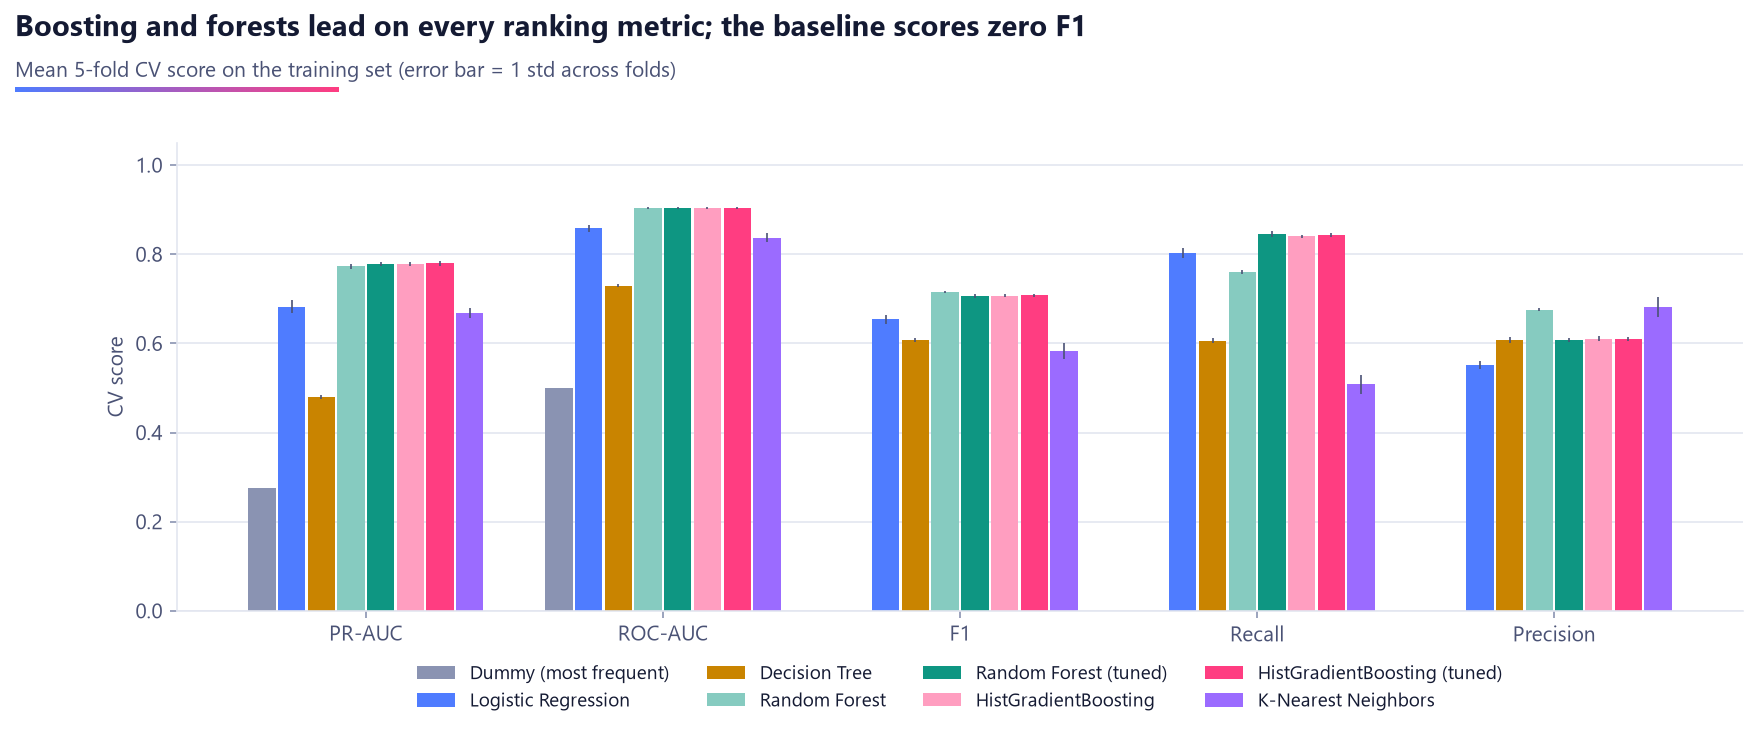

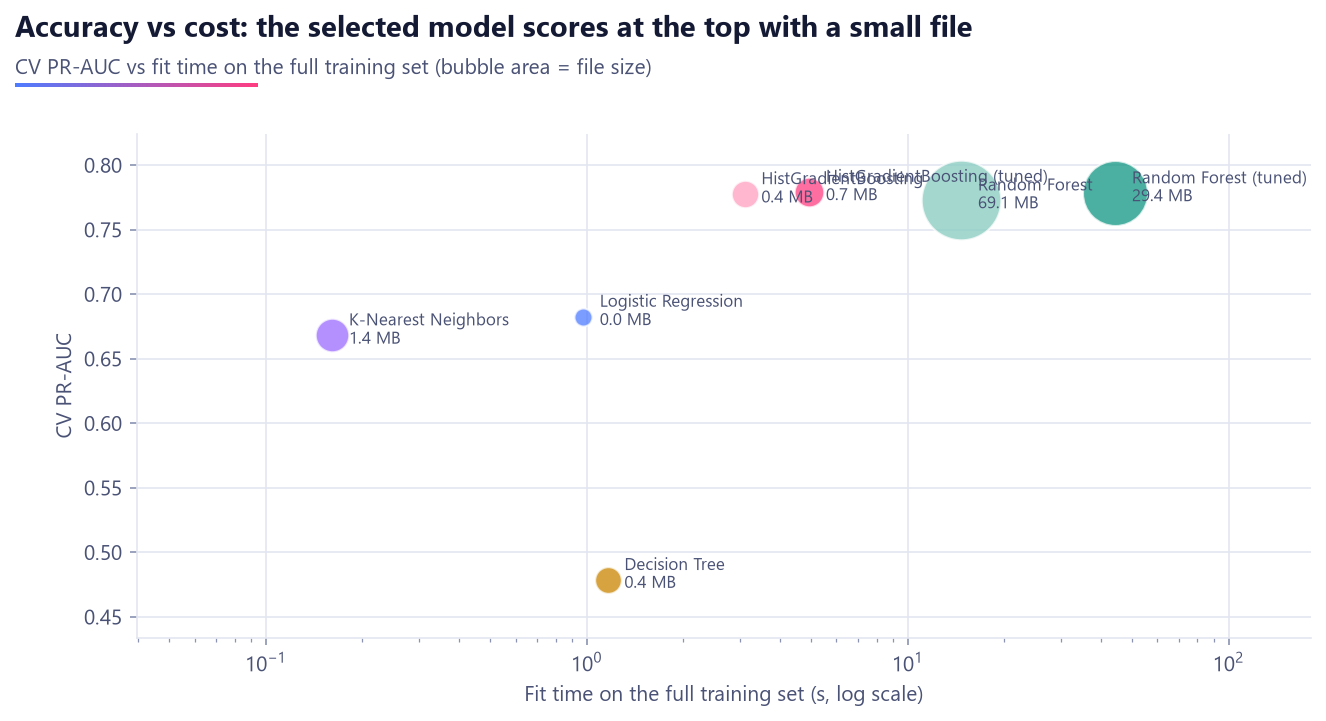

In [9]:
display(Image(FIG / "02_cv_model_comparison.png", width=900))
display(Image(FIG / "14_speed_vs_score.png", width=760))

## 5. ROC and precision-recall curves (test set)

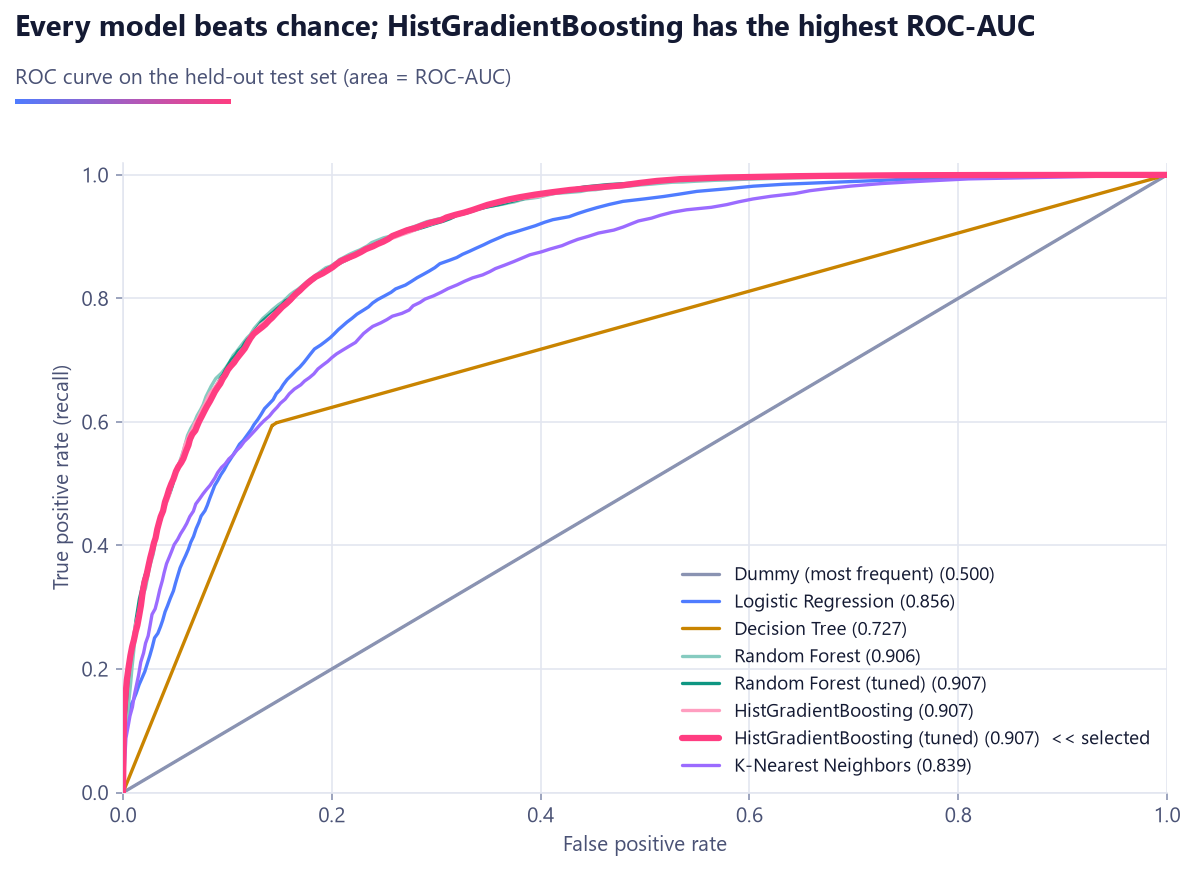

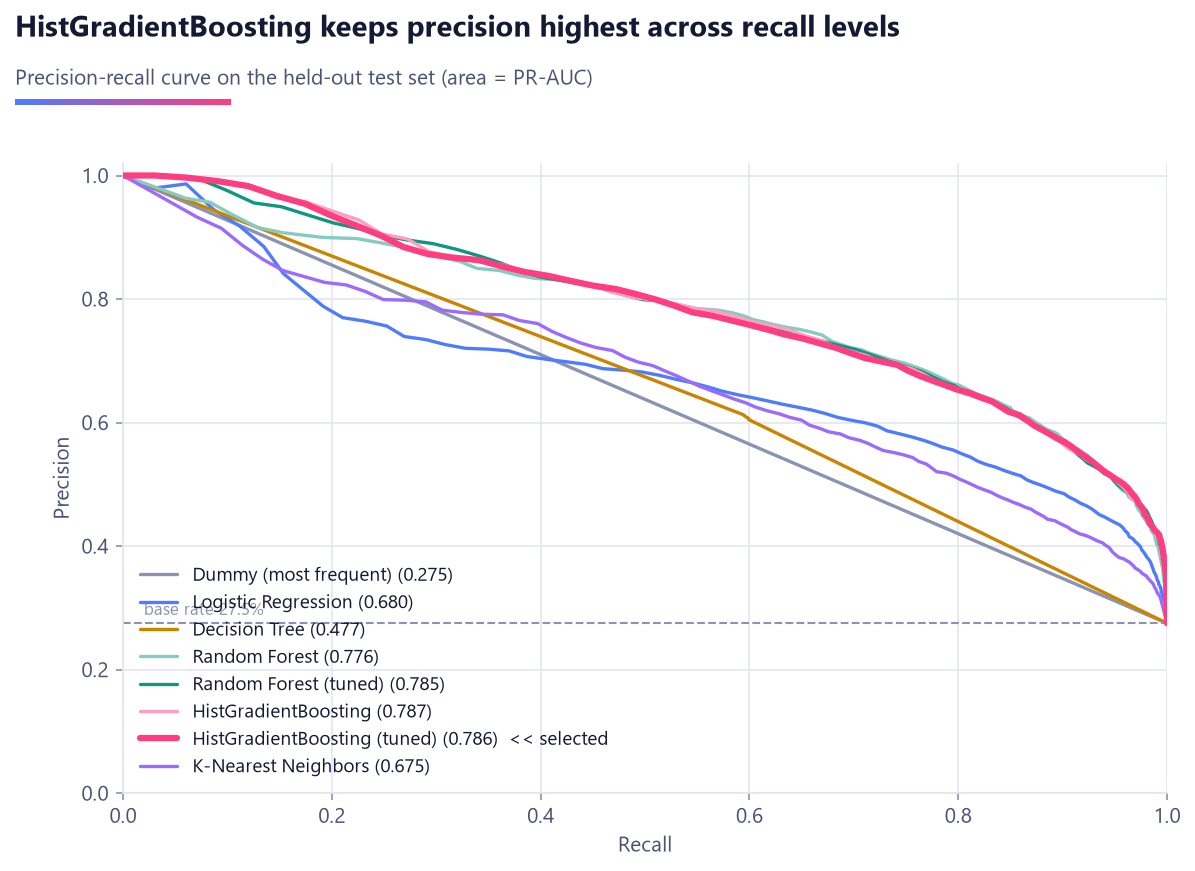

In [10]:
display(Image(FIG / "03_roc_curves.png", width=640))
display(Image(FIG / "04_pr_curves.png", width=640))

## 6. Hyperparameter tuning: RandomizedSearchCV on the top 2 models

Same 5 folds, every metric recorded for every sampled setting, best setting chosen on PR-AUC.

In [11]:
for m in summary["models"]:
    if m["search"]:
        s = m["search"]
        print(
            f"{m['name']}: {s['n_iter']} settings x {s['folds']} folds = {s['fits']} fits "
            f"in {s['search_time_s']:.0f}s"
        )
        print(f"  best params: {s['best_params']}")
        print(f"  CV {label}: {m['cv'][metric]['mean']:.4f} ± {m['cv'][metric]['std']:.4f}")
        base = next(x for x in summary["models"] if x["key"] == m["base"])
        print(
            f"  untuned:     {base['cv'][metric]['mean']:.4f}  ->  gain {m['cv'][metric]['mean'] - base['cv'][metric]['mean']:+.4f}"
        )
        display(pd.DataFrame(s["candidates"]).head(5))

Random Forest (tuned): 12 settings x 5 folds = 60 fits in 240s
  best params: {'n_estimators': 350, 'min_samples_leaf': 4, 'max_features': 0.35, 'max_depth': 18}
  CV PR-AUC: 0.7786 ± 0.0048
  untuned:     0.7731  ->  gain +0.0055


,params,cv,train,chosen
0,"{'n_estimators': 150, 'min_samples_leaf': 2, '...",0.7843,0.9961,False
1,"{'n_estimators': 350, 'min_samples_leaf': 2, '...",0.7835,0.9768,False
2,"{'n_estimators': 350, 'min_samples_leaf': 4, '...",0.7786,0.8990,True
3,"{'n_estimators': 150, 'min_samples_leaf': 8, '...",0.7770,0.8880,False
4,"{'n_estimators': 150, 'min_samples_leaf': 4, '...",0.7762,0.9016,False


HistGradientBoosting (tuned): 20 settings x 5 folds = 100 fits in 232s
  best params: {'min_samples_leaf': 80, 'max_leaf_nodes': 31, 'max_iter': 500, 'learning_rate': 0.05, 'l2_regularization': 1.0}
  CV PR-AUC: 0.7794 ± 0.0051
  untuned:     0.7776  ->  gain +0.0018


,params,cv,train,chosen
0,"{'min_samples_leaf': 10, 'max_leaf_nodes': 127...",0.7859,0.9316,False
1,"{'min_samples_leaf': 40, 'max_leaf_nodes': 127...",0.7849,0.9464,False
2,"{'min_samples_leaf': 20, 'max_leaf_nodes': 127...",0.7847,0.9640,False
3,"{'min_samples_leaf': 10, 'max_leaf_nodes': 63,...",0.7840,0.9204,False
4,"{'min_samples_leaf': 10, 'max_leaf_nodes': 127...",0.7833,0.9994,False


## 7. Overfitting and underfitting

Train scores are the mean over the CV training folds. Rules: a train-CV gap above 0.05 means
overfitting; a small gap but a CV score more than 0.05 below the best model means underfitting.

In [12]:
table = pd.DataFrame(
    [
        {
            "model": m["name"],
            "train": m["train"][metric],
            "cv": m["cv"][metric]["mean"],
            "test": m["test"][metric],
            "train-cv gap": m["gap"],
            "diagnosis": m["diagnosis"]["label"],
            "why": m["diagnosis"]["reason"],
        }
        for m in summary["models"]
    ]
)
table

,model,train,cv,test,train-cv gap,diagnosis,why
0,Dummy (most frequent),0.2751,0.2751,0.2751,0.0000,Baseline,No learning at all: always predicts the majori...
1,Logistic Regression,0.6828,0.6826,0.6802,0.0002,Underfitting,Train and CV are close (gap 0.000) but 0.097 b...
2,Decision Tree,0.9999,0.4790,0.4773,0.5209,Strong overfitting,Train score is 0.521 above CV: it memorises tr...
3,Random Forest,0.9999,0.7731,0.7762,0.2268,Strong overfitting,Train score is 0.227 above CV: it memorises tr...
4,Random Forest (tuned),0.8990,0.7786,0.7851,0.1204,Strong overfitting,Train score is 0.120 above CV: it memorises tr...
5,HistGradientBoosting,0.8586,0.7776,0.7872,0.0810,Mild overfitting,Train score is 0.081 above CV: it memorises tr...
6,HistGradientBoosting (tuned),0.8395,0.7794,0.7856,0.0601,Mild overfitting,Train score is 0.060 above CV: it memorises tr...
7,K-Nearest Neighbors,1.0000,0.6682,0.6755,0.3318,Strong overfitting,Train score is 0.332 above CV: it memorises tr...


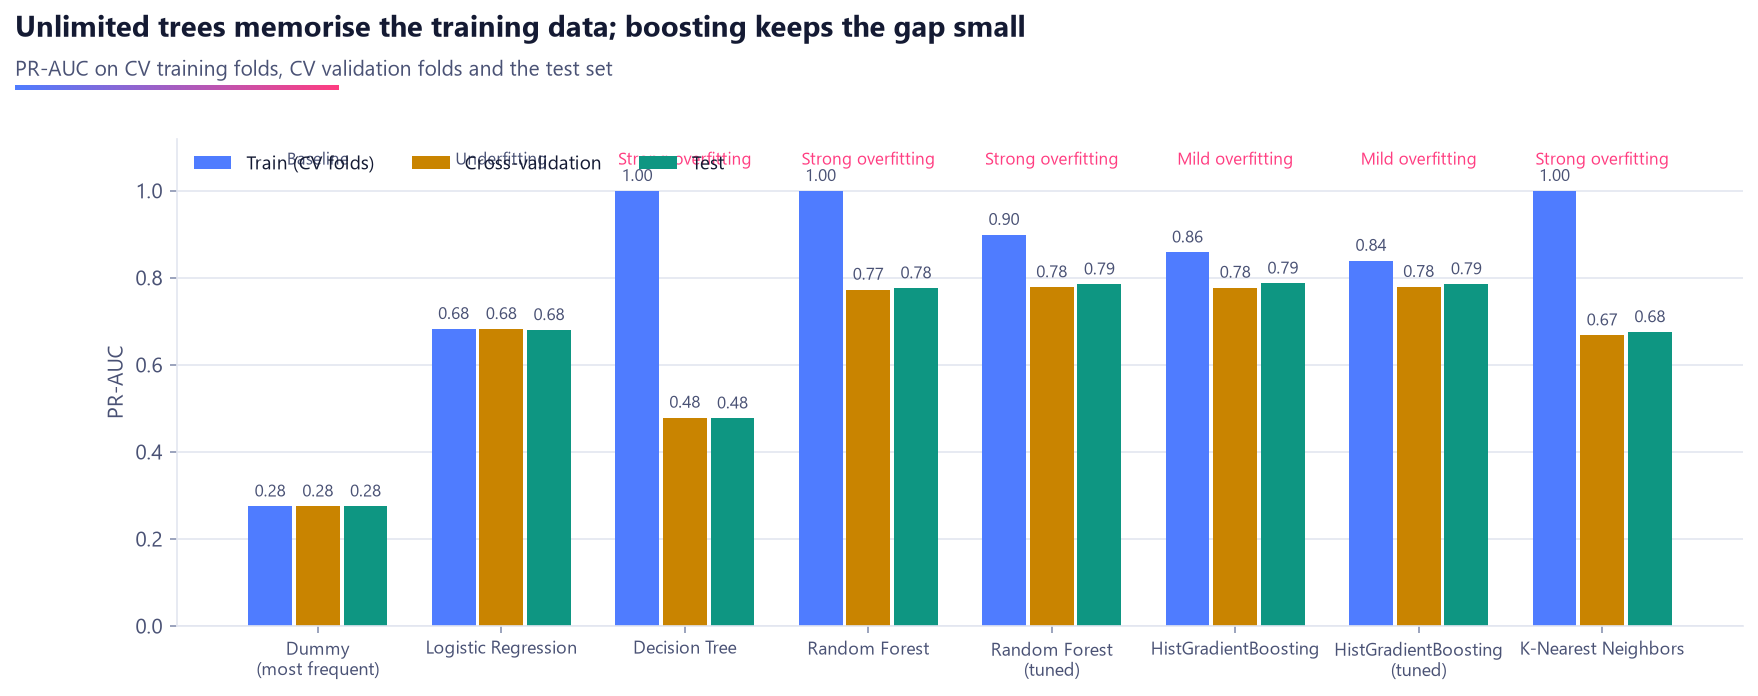

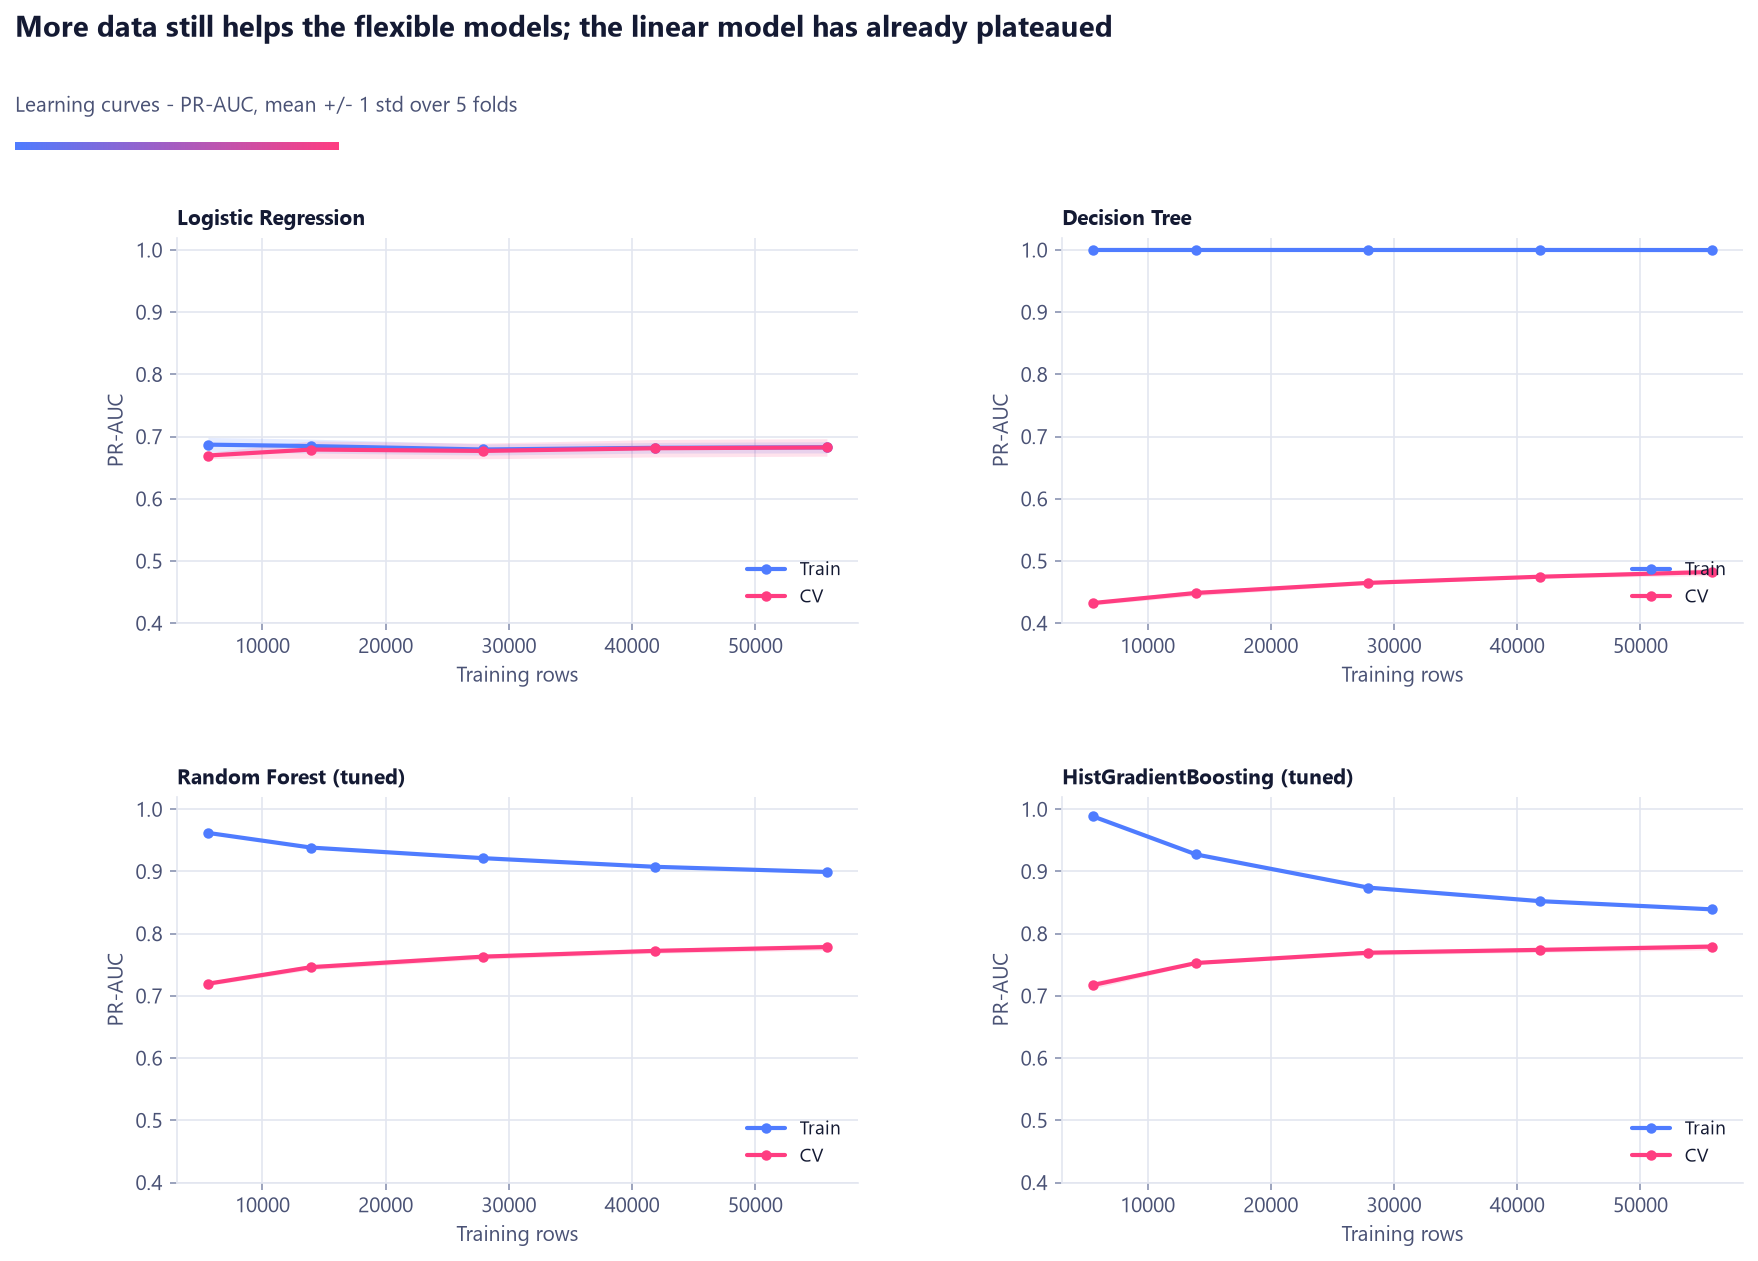

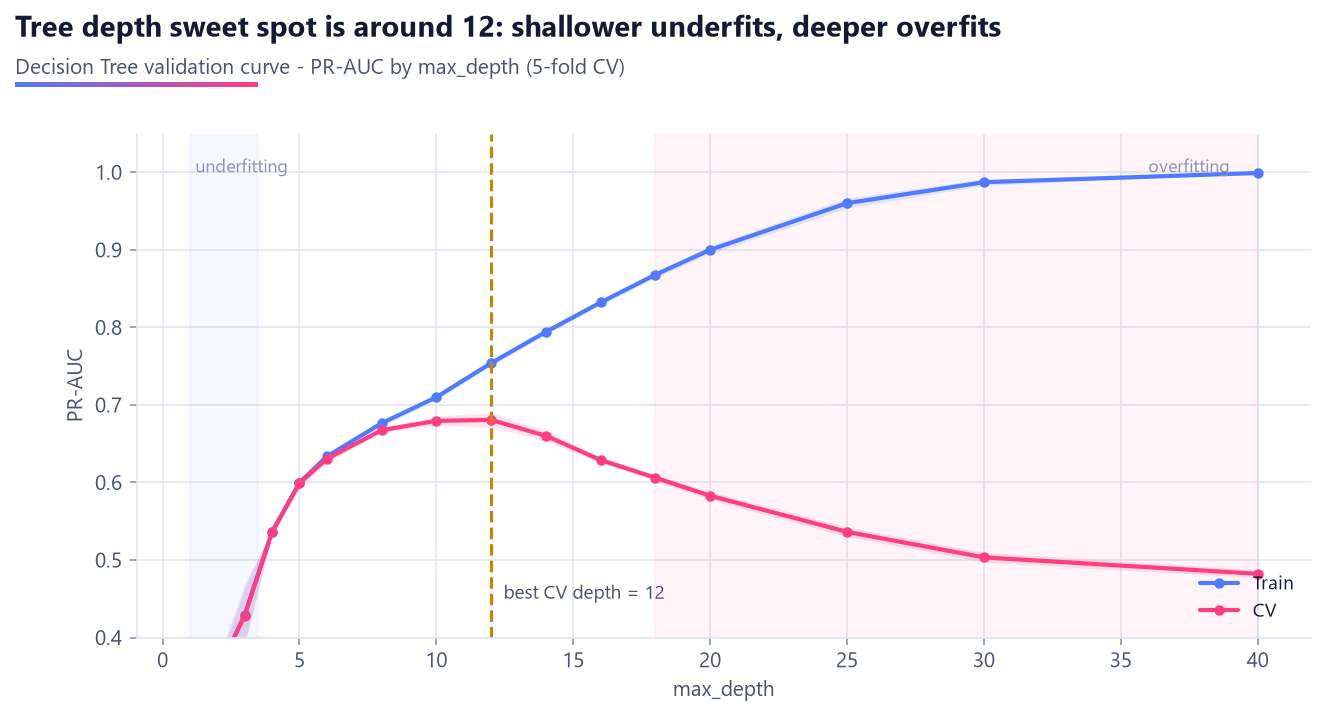

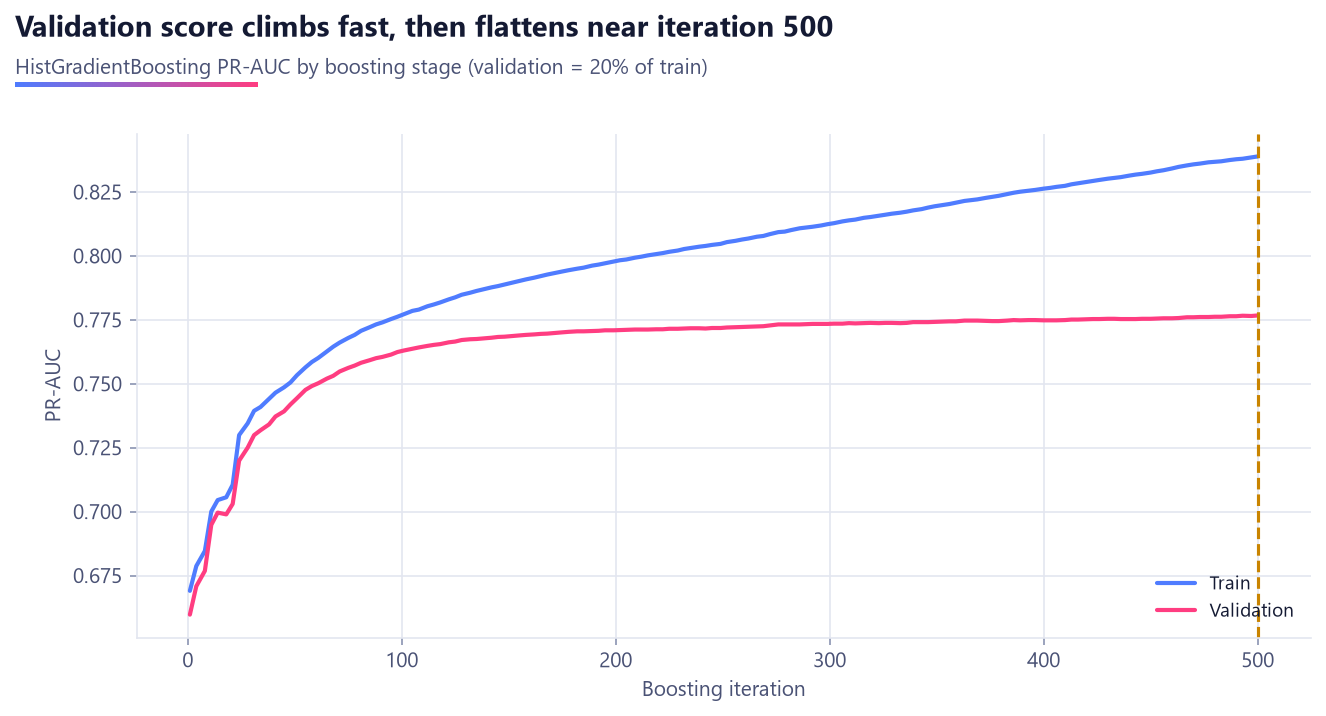

In [13]:
display(Image(FIG / "06_overfitting_gaps.png", width=900))
display(Image(FIG / "07_learning_curves.png", width=900))
display(Image(FIG / "08_validation_curve_depth.png", width=760))
display(Image(FIG / "16_boosting_replay.png", width=760))

## 8. Model selection and justification

The rule is in `src/train.py::select_final_model` and uses **only cross-validation evidence**:

1. Candidates are the models within 0.005 PR-AUC of the best mean CV score (fold noise).
2. Exclude models too big for the 512 MB free host (> 50 MB file).
3. Break ties by the smallest train-CV gap, then file size, then prediction speed.

In [14]:
selection = summary["selection"]
final_rec = next(m for m in summary["models"] if m["key"] == selection["key"])
print(
    "Ranking by CV:",
    [next(m["name"] for m in summary["models"] if m["key"] == k) for k in selection["ranking"]],
)
print("Tied within tolerance:", selection["tied"])
print("Excluded for size:", selection["excluded_for_size"])
print("SELECTED:", final_rec["name"])
print(
    f"  CV {label} {final_rec['cv'][metric]['mean']:.4f} ± {final_rec['cv'][metric]['std']:.4f}, "
    f"gap {final_rec['gap']:.4f} ({final_rec['diagnosis']['label']}), "
    f"{final_rec['size_mb']:.2f} MB, {final_rec['predict_ms_per_1k']:.0f} ms / 1k rows"
)
print("  interpretability:", final_rec["interpretability"])

Ranking by CV: ['HistGradientBoosting (tuned)', 'Random Forest (tuned)', 'HistGradientBoosting', 'Random Forest', 'Logistic Regression', 'K-Nearest Neighbors', 'Decision Tree']
Tied within tolerance: ['hgb_tuned', 'rf_tuned', 'hgb']
Excluded for size: []
SELECTED: HistGradientBoosting (tuned)
  CV PR-AUC 0.7794 ± 0.0051, gap 0.0601 (Mild overfitting), 0.71 MB, 7 ms / 1k rows
  interpretability: Medium: additive trees, explained with permutation importance


## 9. Decision threshold (out-of-fold, not the test set)

The model outputs a probability; 0.5 is an arbitrary cut. Out-of-fold predictions on the
training set (each row predicted by a model that never saw it) are used to pick the threshold
that maximises F1. The alternative "recall >= 80%" threshold is shown too.

In [15]:
th = summary["threshold"]
print(
    f"Chosen threshold: {th['chosen']:.2f} ({th['strategy']}); recall>={th['recall_target']:.0%} target -> {th['recall_target_threshold']:.2f}"
)
pd.DataFrame(
    {"OOF @ 0.50": th["oof_metrics_default"], f"OOF @ {th['chosen']:.2f}": th["oof_metrics_chosen"]}
).rename(index=config.METRIC_LABELS)

Chosen threshold: 0.59 (max_f1); recall>=80% target -> 0.55


,OOF @ 0.50,OOF @ 0.59
Accuracy,0.8088,0.8308
Precision,0.6103,0.6659
Recall,0.8436,0.7726
F1,0.7082,0.7153
ROC-AUC,0.9038,0.9038
PR-AUC,0.7792,0.7792


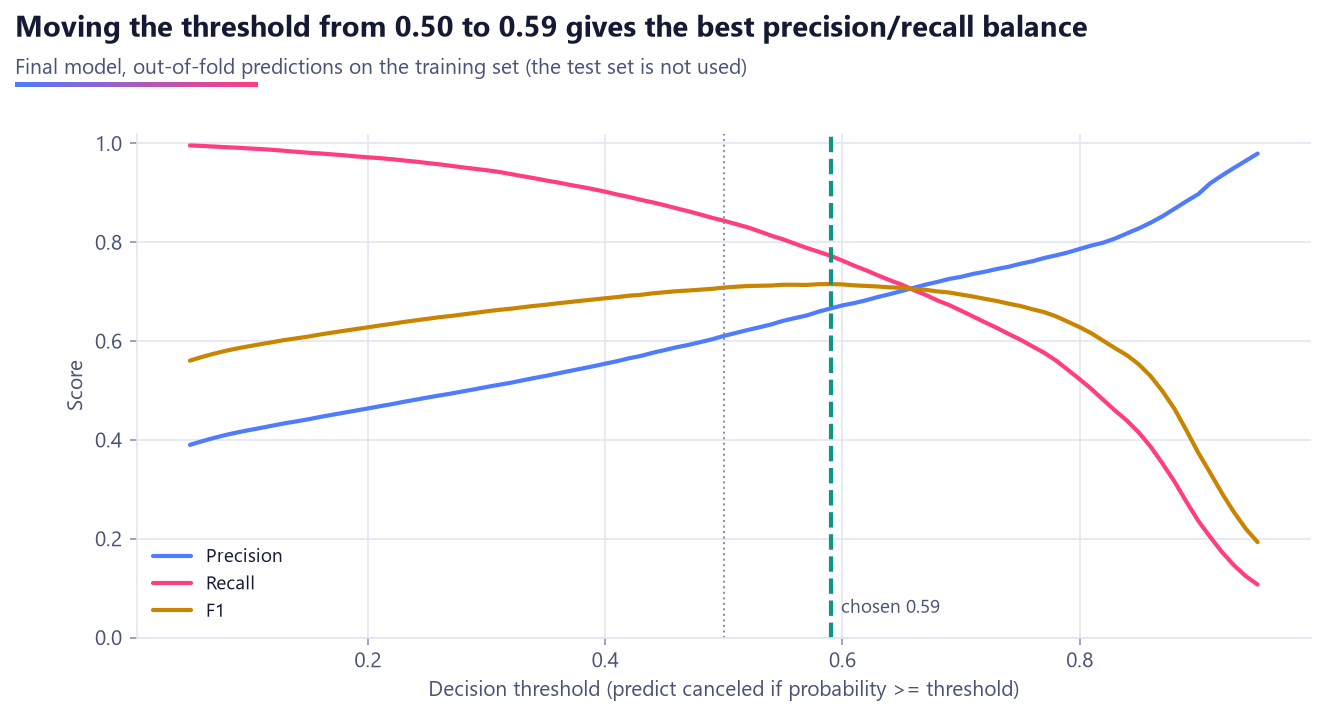

In [16]:
display(Image(FIG / "09_threshold_tuning.png", width=760))

## 10. Final evaluation on the untouched test set

The saved final model (`models/final_model.joblib`) is loaded and scored live on the test set.

In [17]:
model = joblib.load(config.FINAL_MODEL_PATH)
proba = model.predict_proba(dataset.x_test)[:, 1]
threshold = summary["final"]["threshold"]
pd.DataFrame(
    {
        "threshold 0.50": compute_metrics(dataset.y_test, proba),
        f"tuned {threshold:.2f}": compute_metrics(dataset.y_test, proba, threshold),
    }
).rename(index=config.METRIC_LABELS)

,threshold 0.50,tuned 0.59
Accuracy,0.8129,0.8325
Precision,0.6153,0.6688
Recall,0.8537,0.7752
F1,0.7152,0.7181
ROC-AUC,0.9069,0.9069
PR-AUC,0.7856,0.7856


In [18]:
pd.DataFrame(report_dict(dataset.y_test, proba, threshold)).T

,precision,recall,f1-score,support
Not canceled,0.9092,0.8543,0.8809,12643.0000
Canceled,0.6688,0.7752,0.7181,4799.0000
accuracy,0.8325,0.8325,0.8325,0.8325
macro avg,0.7890,0.8147,0.7995,17442.0000
weighted avg,0.8430,0.8325,0.8361,17442.0000


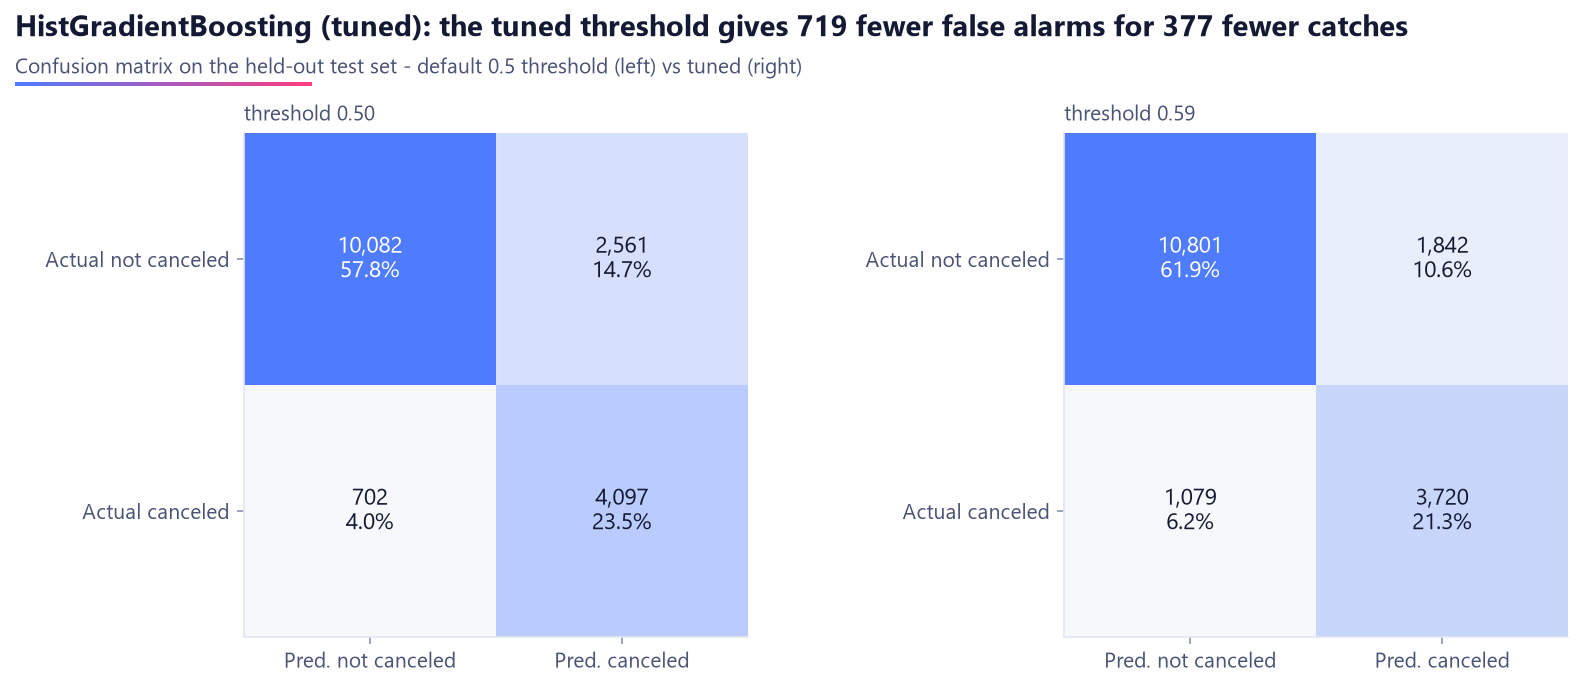

In [19]:
display(Image(FIG / "05_confusion_matrix.png", width=860))

## 11. Explainability

Permutation importance of the final model on the test set (raw input columns, so a categorical
column counts as one feature), plus the impurity importances of the tree models.

In [20]:
pd.DataFrame(summary["permutation"]).head(12)

,feature,importance_mean,importance_std
0,is_domestic,0.1360,0.0025
1,lead_time,0.1151,0.0042
2,total_of_special_requests,0.1073,0.0041
3,agent,0.1048,0.0058
4,market_segment,0.0894,0.0050
5,required_car_parking_spaces,0.0661,0.0020
6,previous_cancel_ratio,0.0521,0.0043
7,customer_type,0.0468,0.0024
8,deposit_type,0.0389,0.0031
9,country,0.0171,0.0007


In [21]:
for item in summary["insights"]:
    print("-", item["text"])

- Bookings with is_domestic = 1 cancel 36%, vs 24% when it is 0.
- Top quarter of lead_time (>= 125) cancels 38%, bottom quarter (<= 11) 10%.
- Bookings with 1+ total_of_special_requests cancel 22%, vs 33% with none.
- agent = 9 cancels 40% of the time, vs 6% for 28.
- market_segment = Online TA cancels 35% of the time, vs 12% for Corporate.
- Bookings with 1+ required_car_parking_spaces cancel 0%, vs 30% with none.
- Bookings with previous_cancel_ratio > 0 cancel 67%, vs 27% otherwise.
- customer_type = Transient cancels 30% of the time, vs 15% for Transient-Party.


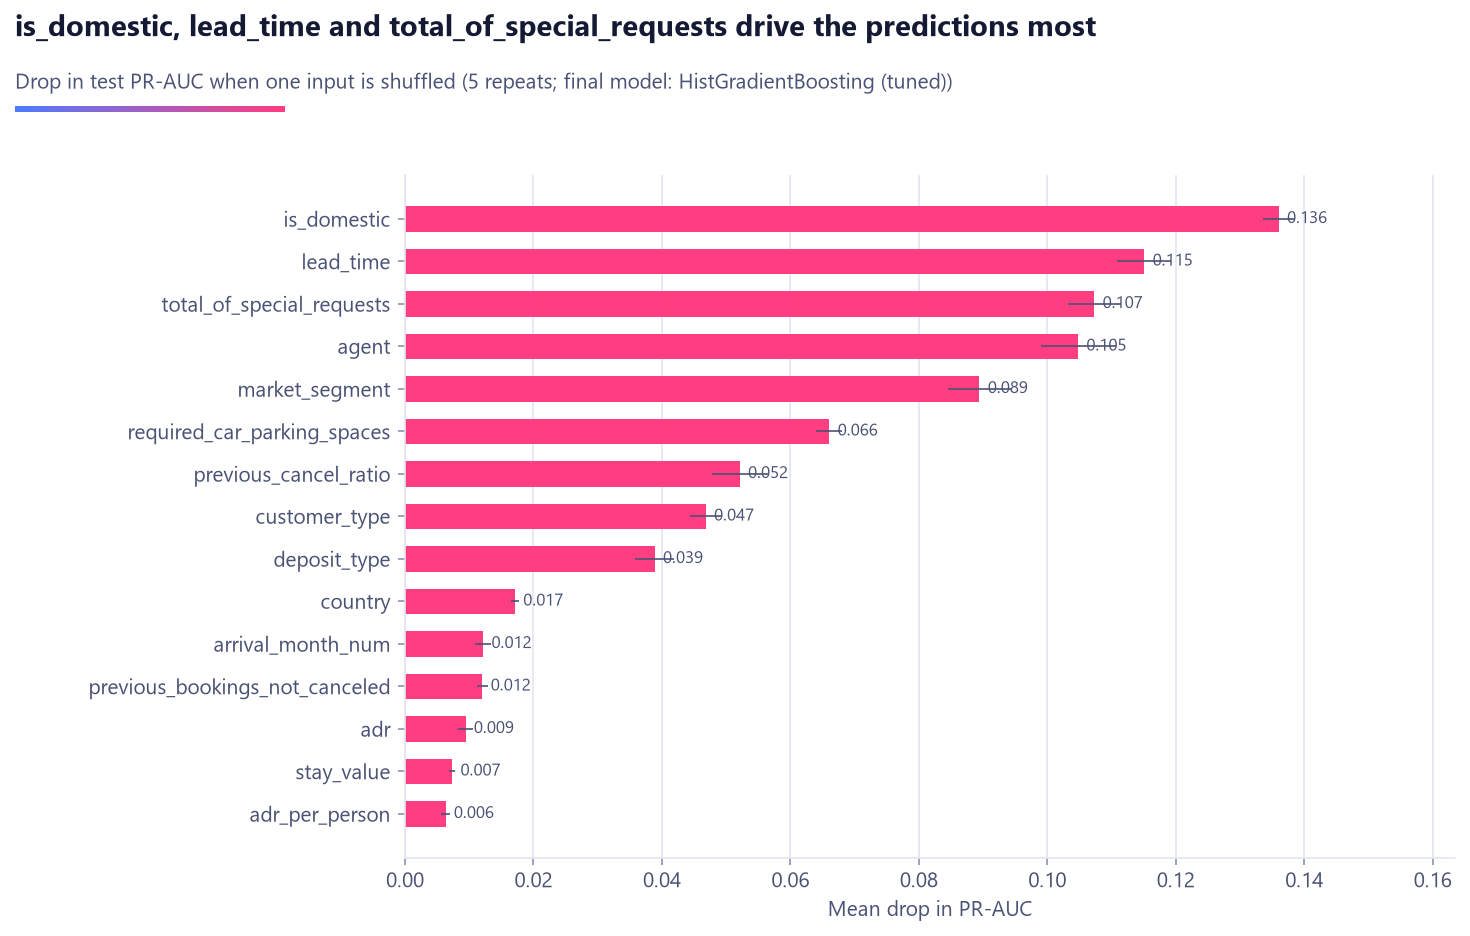

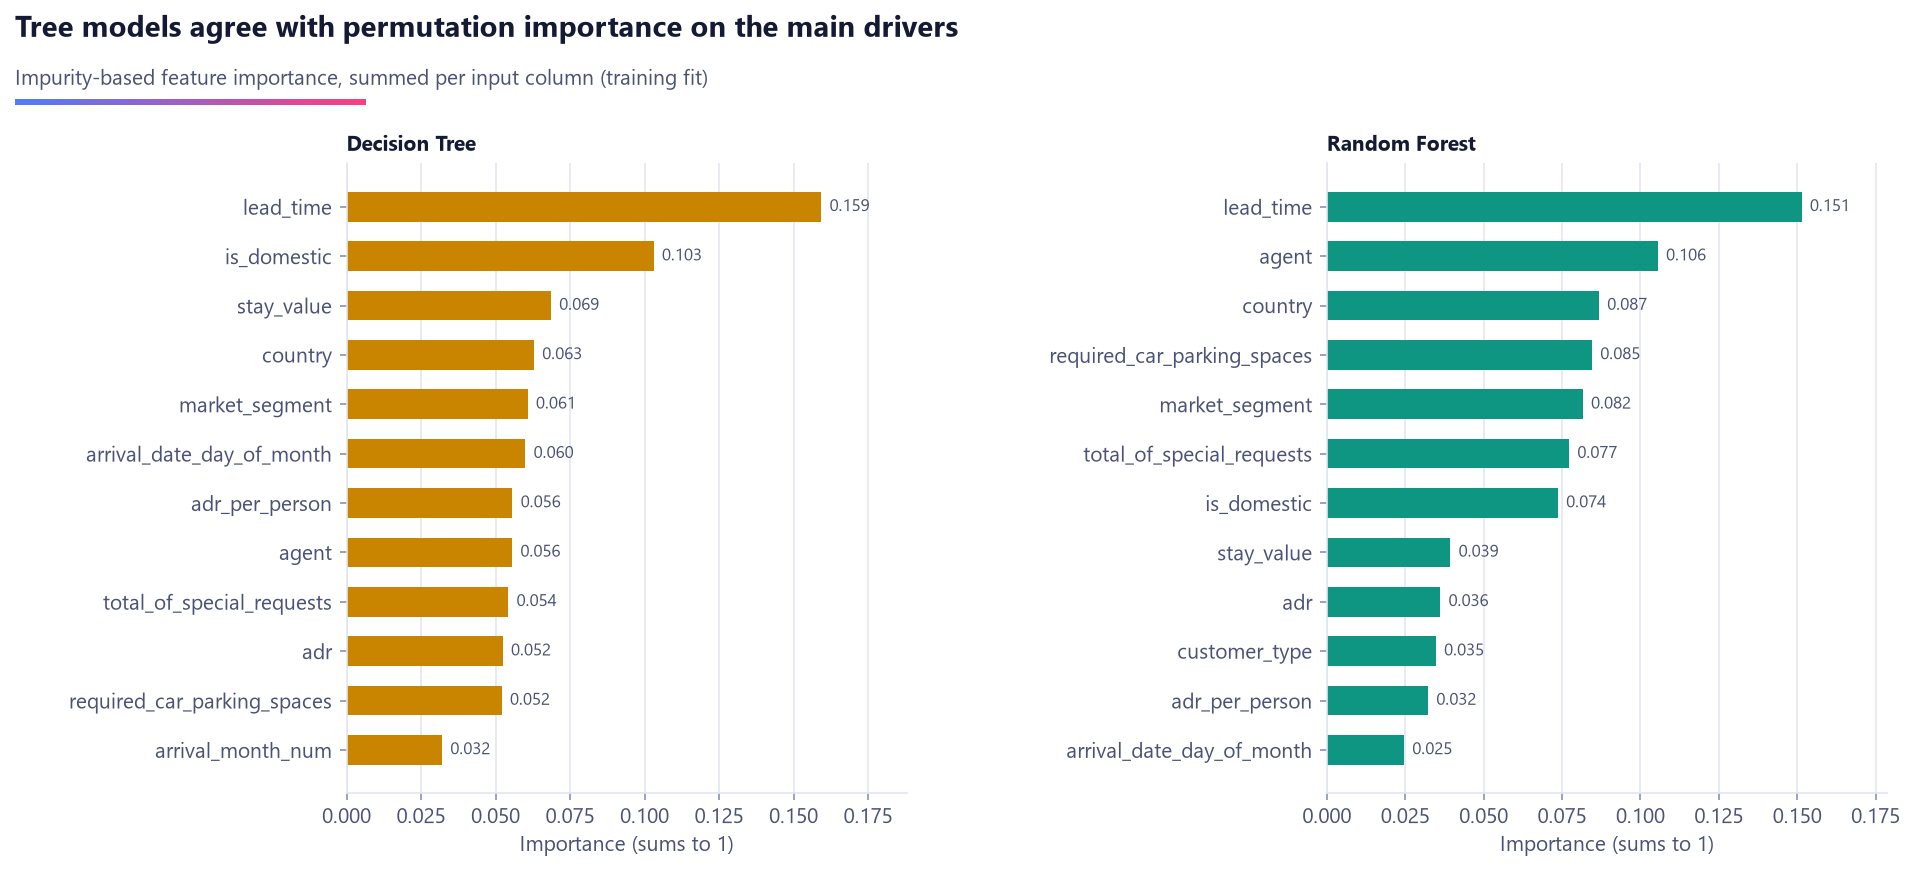

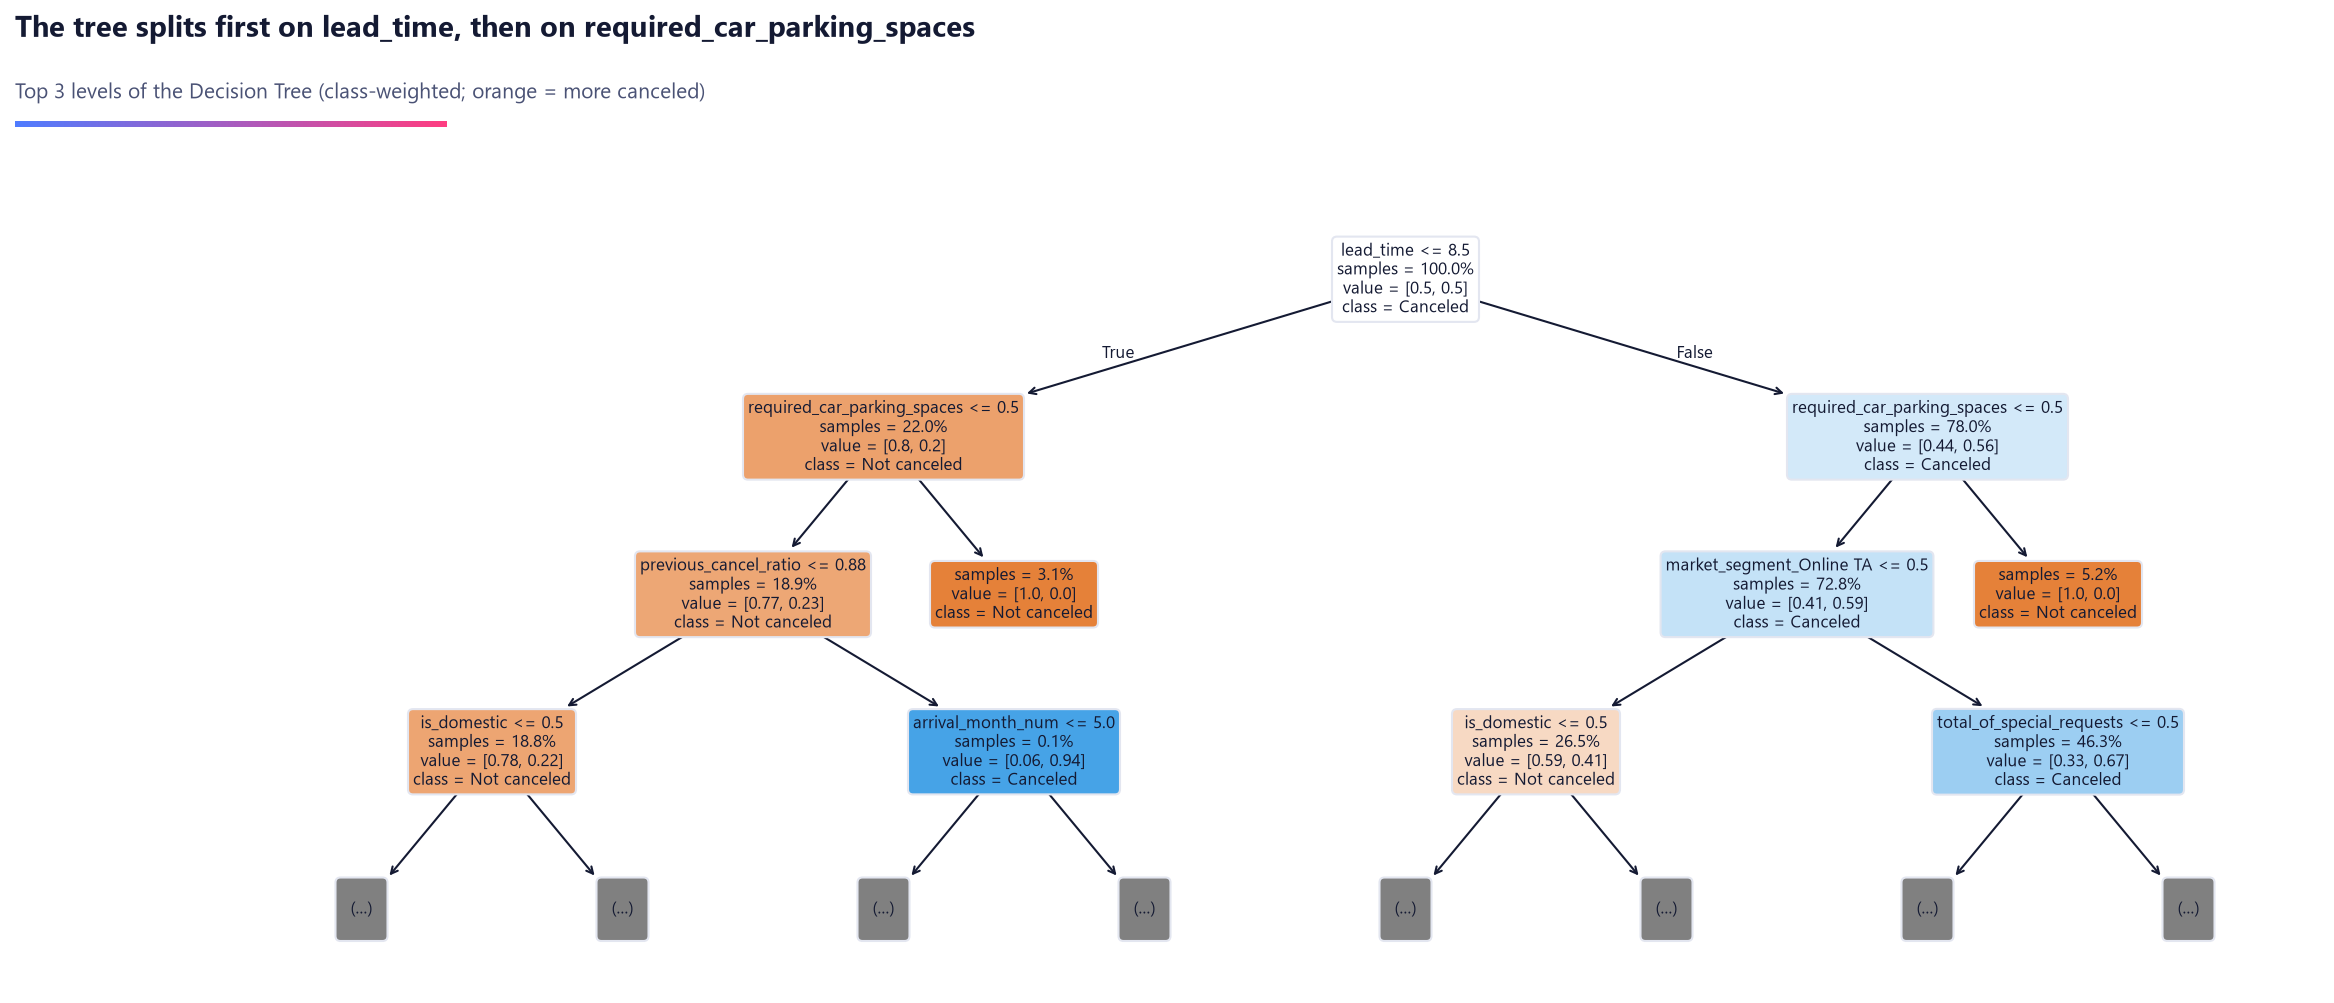

In [22]:
display(Image(FIG / "10_permutation_importance.png", width=820))
display(Image(FIG / "11_tree_feature_importance.png", width=900))
display(Image(FIG / "12_decision_tree_top_levels.png", width=980))

## 12. Temporal validation: does performance hold over time?

In [23]:
t = summary["temporal"]
print(
    f"Train arrivals {t['train_period'][0]} -> {t['train_period'][1]} ({t['train_rows']:,} rows, {t['train_cancel_rate']:.1%} canceled)"
)
print(
    f"Test  arrivals {t['test_period'][0]} -> {t['test_period'][1]} ({t['test_rows']:,} rows, {t['test_cancel_rate']:.1%} canceled)"
)
pd.DataFrame(
    [
        {
            "model": m["name"],
            f"random split {label}": m["test"][metric],
            f"temporal {label}": t["metrics"][m["key"]][metric],
            "change": t["metrics"][m["key"]][metric] - m["test"][metric],
        }
        for m in summary["models"]
        if m["key"] != "dummy"
    ]
)

Train arrivals 2015-07-01 -> 2017-05-01 (69,664 rows, 25.7% canceled)
Test  arrivals 2017-05-02 -> 2017-08-31 (17,544 rows, 34.7% canceled)


,model,random split PR-AUC,temporal PR-AUC,change
0,Logistic Regression,0.6802,0.6910,0.0108
1,Decision Tree,0.4773,0.4744,-0.0029
2,Random Forest,0.7762,0.6832,-0.0930
3,Random Forest (tuned),0.7851,0.6906,-0.0945
4,HistGradientBoosting,0.7872,0.6990,-0.0882
5,HistGradientBoosting (tuned),0.7856,0.7028,-0.0828
6,K-Nearest Neighbors,0.6755,0.6108,-0.0647


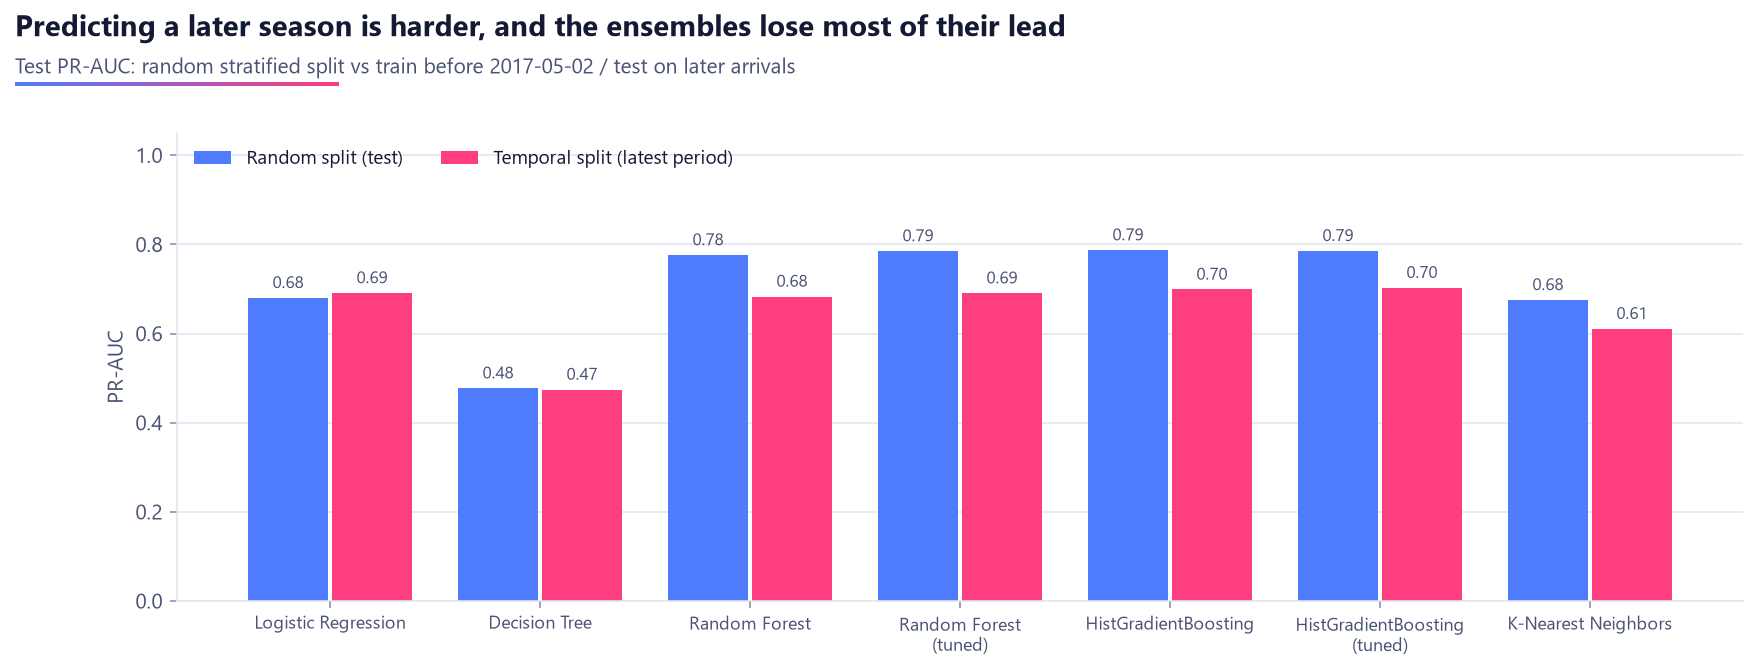

In [24]:
display(Image(FIG / "13_temporal_vs_random.png", width=900))

## 13. Conclusions

* **Model**: the selected model has the best cross-validated PR-AUC, a small train-CV gap,
  and a file small and fast enough for a free 512 MB host (section 8).
* **Generalisation**: CV and test scores agree closely, so the validation setup works. The
  unconstrained Decision Tree and KNN clearly overfit; Logistic Regression underfits the
  non-linear patterns.
* **Business use**: the tuned threshold trades a little precision for more caught
  cancellations. The web app's cost calculator lets a hotel pick a threshold from its own costs.
* **Caveat**: on a future period the score drops and the cancel rate shifts (section 12), so
  in production the model should be retrained regularly and the threshold re-checked each season.

All decisions are logged in `docs/decisions.md`.